# DSK807 – Applied Machine Learning
## L07 Hands-on: Decision Trees

We will investigate:

### Part A: Classification
- a real medical classification dataset;
- Logistic Regression, SVC, and Decision Tree;
- why scaling matters for some models but not Decision Trees;
- tree depth and overfitting;
- confusion matrices and classification metrics;
- feature importance;
- visualizing and interpreting a tree;
- hyperparameter tuning with cross-validation.

### Part B: Regression
- the **Ames Housing** dataset with real house-sale data;
- missing values and preprocessing;
- Linear Regression vs. Decision Tree Regression;
- the effect of scaling;
- MSE, RMSE, MAE and R²;
- regression-tree feature importance;
- how tree depth changes train/test performance.

There are short **student challenges** throughout the notebook.


## 1. Imports


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

pd.set_option("display.max_columns", 100)


# **Part A: Classification**

We use scikit-learn's **Breast Cancer Wisconsin (Diagnostic)** dataset.

The task is binary classification: predict whether a tumor is **malignant** or **benign** from measurements computed from digitized images of cell nuclei.

This dataset is useful here because its features have very different numerical scales — exactly what we need to compare scale-sensitive models with a Decision Tree.


## 2. Load and inspect the dataset


In [2]:
data = load_breast_cancer(as_frame=True)

df = data.frame.copy()

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
features = [
    "mean radius",
    "mean texture",
    "mean perimeter",
    "mean smoothness",
    "mean concavity"
]

X = df[features]
y = df["target"]

print("Features:")
display(X.head())

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "malignant", 1: "benign"}))

Features:


,mean radius,mean texture,mean perimeter,mean smoothness,mean concavity
0,17.99,10.38,122.80,0.11840,0.3001
1,20.57,17.77,132.90,0.08474,0.0869
2,19.69,21.25,130.00,0.10960,0.1974
3,11.42,20.38,77.58,0.14250,0.2414
4,20.29,14.34,135.10,0.10030,0.1980



Class distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


In [4]:
# Look at feature scales
display(
    X.agg(["min", "max", "mean", "std"]).T
     .sort_values("std", ascending=False)
     .head(15)
)


,min,max,mean,std
mean perimeter,43.79000,188.5000,91.969033,24.298981
mean texture,9.71000,39.2800,19.289649,4.301036
mean radius,6.98100,28.1100,14.127292,3.524049
mean concavity,0.00000,0.4268,0.088799,0.079720
mean smoothness,0.05263,0.1634,0.096360,0.014064


### Think before running the next cells

Some features are measured on very different scales.

**Question:** Which of these models do you expect to be affected by scaling?

- Logistic Regression
- SVC with RBF kernel
- Decision Tree


## 3. Train/test split


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y # 這確保有按照比例來作
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).sort_index())


Train: (426, 5)
Test : (143, 5)

Training class distribution:
target
0    0.373239
1    0.626761
Name: proportion, dtype: float64


## 4. First comparison — WITHOUT scaling


In [6]:
models_unscaled = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "SVC (RBF)": SVC(kernel="rbf"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    )
}

unscaled_results = []

for name, model in models_unscaled.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    unscaled_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred)
    })

pd.DataFrame(unscaled_results).sort_values(
    "Accuracy", ascending=False
)


,Model,Accuracy
0,Logistic Regression,0.937063
2,Decision Tree,0.930070
1,SVC (RBF),0.874126


## 5. Now scale the features


In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models_scaled = {
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "SVC (RBF)": SVC(kernel="rbf"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    )
}

scaled_results = []

for name, model in models_scaled.items():
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)

    scaled_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred)
    })

pd.DataFrame(scaled_results).sort_values(
    "Accuracy", ascending=False
)


,Model,Accuracy
1,SVC (RBF),0.944056
2,Decision Tree,0.930070
0,Logistic Regression,0.902098


## 6. Compare scaled vs. unscaled


In [8]:
comparison = (
    pd.DataFrame(unscaled_results)
    .merge(
        pd.DataFrame(scaled_results),
        on="Model",
        suffixes=(" — Unscaled", " — Scaled")
    )
)

comparison["Difference"] = (
    comparison["Accuracy — Scaled"]
    - comparison["Accuracy — Unscaled"]
)

display(comparison.round(4))


,Model,Accuracy — Unscaled,Accuracy — Scaled,Difference
0,Logistic Regression,0.9371,0.9021,-0.0350
1,SVC (RBF),0.8741,0.9441,0.0699
2,Decision Tree,0.9301,0.9301,0.0000


### Why does scaling not affect a Decision Tree?

A tree asks questions such as:

`mean radius <= 14.7?`

If a feature is transformed linearly:

`mean radius_scaled <= 0.23?`

the **ordering of the samples remains the same**. The tree can therefore make an equivalent split.

This is very different from SVC and Logistic Regression, whose optimization depends on numerical feature magnitudes.

> Small numerical differences can occasionally occur because of floating-point/tie behavior, but scaling is generally unnecessary for ordinary Decision Trees.


## 7. Verify this directly


In [9]:
tree_unscaled = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree_scaled = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)

tree_unscaled.fit(X_train, y_train)
tree_scaled.fit(X_train_scaled, y_train)

pred_unscaled = tree_unscaled.predict(X_test)
pred_scaled = tree_scaled.predict(X_test_scaled)

print("Unscaled accuracy:", accuracy_score(y_test, pred_unscaled))
print("Scaled accuracy:  ", accuracy_score(y_test, pred_scaled))
print("Identical predictions:",
      np.array_equal(pred_unscaled, pred_scaled))


Unscaled accuracy: 0.9300699300699301
Scaled accuracy:   0.9300699300699301
Identical predictions: True


## 8. Decision Tree: inspect more than accuracy

Accuracy alone can hide the kinds of mistakes the model makes.


              precision    recall  f1-score   support

   malignant       0.92      0.89      0.90        53
      benign       0.93      0.96      0.95        90

    accuracy                           0.93       143
   macro avg       0.93      0.92      0.92       143
weighted avg       0.93      0.93      0.93       143



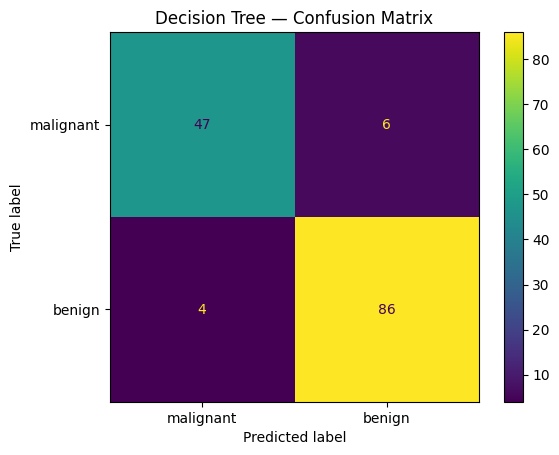

In [10]:
print(
    classification_report(
        y_test,
        pred_unscaled,
        target_names=data.target_names
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_unscaled,
    display_labels=data.target_names
)

plt.title("Decision Tree — Confusion Matrix")
plt.show()


## 9. Visualize the learned tree


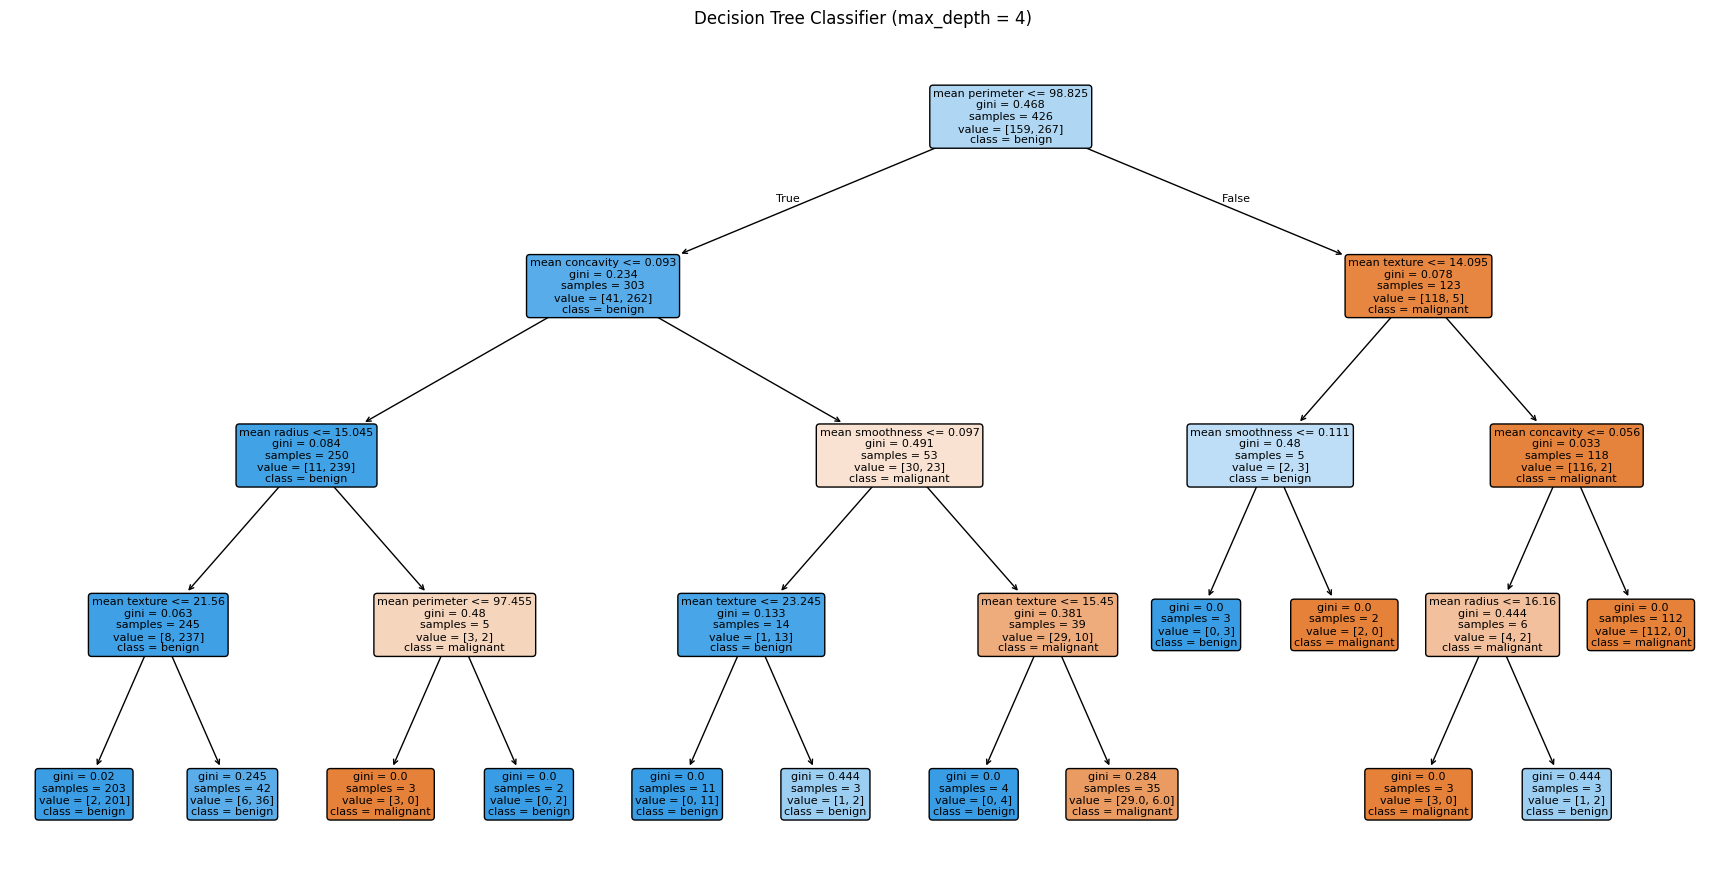

In [11]:
plt.figure(figsize=(22, 11))

plot_tree(
    tree_unscaled,
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier (max_depth = 4)")
plt.show()


### Reading a node

For each node, identify:

1. the feature and threshold;
2. the Gini impurity;
3. the number of training samples;
4. the class counts;
5. the predicted class.

Choose one path from the root to a leaf and explain it in plain language.


流程是「一個欄位、一個欄位地試」，最後從所有候選裡挑一個最好的。


在某個節點上：

1. 拿第一個欄位，只看這一欄，把值排序，在每兩個相鄰值中間放一個候選切點。
2. 每個候選切點都切一次，用 y 算訊號。
3. 換下一個欄位，重複 1 和 2。
4. 所有欄位的所有候選切點都算完之後，挑訊號最大的那一個。

每一刀只用一個欄位、一個切點，不會同時切兩個欄位。


## 10. Feature Importance


In [12]:
importance = pd.Series(
    tree_unscaled.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importance.head(15).to_frame("importance"))


,importance
mean perimeter,0.702866
mean concavity,0.145547
mean smoothness,0.067895
mean texture,0.057669
mean radius,0.026023


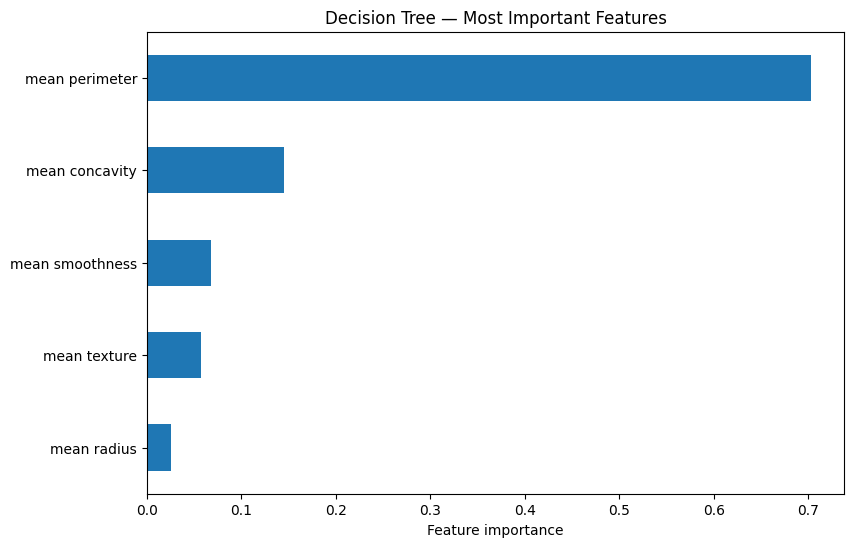

In [13]:
plt.figure(figsize=(9, 6))

importance.head(12).sort_values().plot(kind="barh")

plt.xlabel("Feature importance")
plt.title("Decision Tree — Most Important Features")
plt.show()


### What does Decision Tree feature importance mean?

Scikit-learn's default `feature_importances_` measures the **total weighted reduction in impurity** produced by splits using each feature.

The importances sum to 1.

Important caution: this is **model-specific importance**, not proof that a feature is causally important. Impurity-based importance can also favor features with many possible split points.


In [14]:
print("Sum of feature importances:",
      tree_unscaled.feature_importances_.sum())


Sum of feature importances: 1.0


## 11. Tree depth and overfitting


In [15]:
depth_results = []

for depth in range(1, 16):
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    depth_results.append({
        "max_depth": depth,
        "Train accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test)
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)


,max_depth,Train accuracy,Test accuracy
0,1,0.892019,0.881119
1,2,0.910798,0.888112
2,3,0.946009,0.930070
3,4,0.962441,0.930070
4,5,0.971831,0.930070
5,6,0.981221,0.951049
6,7,0.995305,0.916084
7,8,1.000000,0.937063
8,9,1.000000,0.937063
9,10,1.000000,0.937063


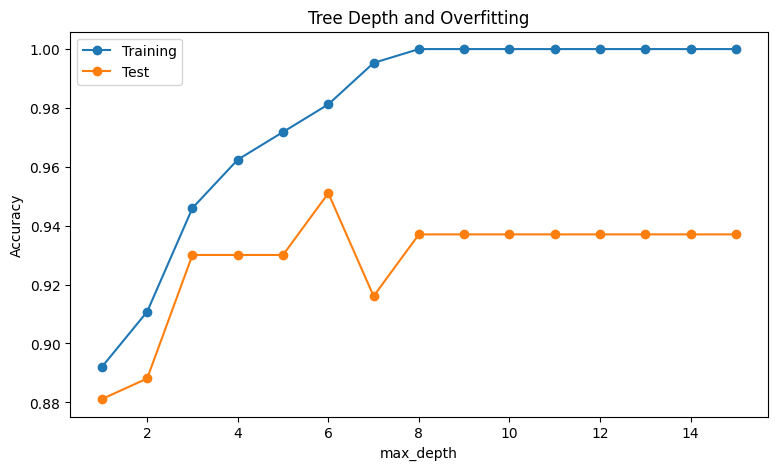

In [16]:
plt.figure(figsize=(9, 5))

plt.plot(
    depth_df["max_depth"],
    depth_df["Train accuracy"],
    marker="o",
    label="Training"
)

plt.plot(
    depth_df["max_depth"],
    depth_df["Test accuracy"],
    marker="o",
    label="Test"
)

plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Tree Depth and Overfitting")
plt.legend()
plt.show()


### Challenge 1

From the graph:

- At what depth does training accuracy become very high?
- Does test accuracy keep improving?
- Which depth would you choose **based only on this one test split**?
- Why is repeatedly choosing hyperparameters from the test set bad practice?

We will now use cross-validation instead.


## 12. Tune the tree with cross-validation


In [17]:
param_grid = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10]
}
# min_samples_split 決定的是：一個節點至少要有幾筆資料，才被允許再往下切。 不到這個數量的節點，就算裡面的資料還很混雜，也直接變成葉節點，用多數決給出答案。
# sklearn 的預設值是 2，也就是只要有 2 筆以上、而且還沒純，就可以切。這等於幾乎沒有限制

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV accuracy:", round(grid.best_score_, 4))
print("Test accuracy:", round(grid.score(X_test, y_test), 4))


Best parameters: {'max_depth': 6, 'min_samples_leaf': 2, 'min_samples_split': 2}
Best CV accuracy: 0.9225
Test accuracy: 0.9301


### Challenge 2

Try changing the scoring metric in `GridSearchCV` from:

`scoring="accuracy"`

to:

`scoring="f1"`

Do you obtain the same tree parameters?

What does this tell you about the phrase **"best model"**?


# **Part B: Regression with Real House Prices**

We now use the **Ames Housing** dataset distributed through OpenML.

It contains residential property sales from Ames, Iowa, including sale price and many characteristics of each house.

We deliberately use a manageable subset of meaningful **numeric features** so that the focus remains on regression trees rather than categorical encoding.

> `fetch_openml()` downloads the dataset the first time it is run, so this section requires internet access in Colab.


## 13. Load the Ames Housing dataset


In [18]:
ames = fetch_openml(
    name="house_prices",
    as_frame=True,
    parser="auto"
)

housing = ames.frame.copy()

print("Dataset shape:", housing.shape)
display(housing.head())


Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',None,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 14. Select features and inspect missing values


In [19]:
features = [
    "OverallQual",   # overall material/finish quality
    "GrLivArea",     # above-ground living area
    "GarageCars",    # garage capacity
    "TotalBsmtSF",   # basement area
    "FullBath",      # full bathrooms
    "YearBuilt",     # year built
    "YearRemodAdd",  # remodeling year
    "1stFlrSF",      # first-floor area
    "TotRmsAbvGrd"   # rooms above ground
]

X_house = housing[features].copy()
y_house = housing["SalePrice"].astype(float)

print("Target: SalePrice")
print("\nMissing values:")
display(X_house.isna().sum().sort_values(ascending=False))

print("\nSale price summary:")
display(y_house.describe())


Target: SalePrice

Missing values:


OverallQual     0
GrLivArea       0
GarageCars      0
TotalBsmtSF     0
FullBath        0
YearBuilt       0
YearRemodAdd    0
1stFlrSF        0
TotRmsAbvGrd    0
dtype: int64


Sale price summary:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

### Challenge 3: Data quality

Before training:

1. Which selected features contain missing values?
2. Why should we fit an imputer using **training data only**?
3. What would be wrong with filling missing values before the train/test split?


## 15. Train/test split


In [20]:
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    X_house,
    y_house,
    test_size=0.20,
    random_state=42
)

print("Training houses:", len(Xh_train))
print("Test houses:", len(Xh_test))


Training houses: 1168
Test houses: 292


## 16. Build preprocessing pipelines

Both models receive median imputation.

For the first comparison we also apply `StandardScaler`.

This lets us later test what happens when scaling is removed.


In [32]:
linear_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

tree_scaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

linear_scaled.fit(Xh_train, yh_train)
tree_scaled.fit(Xh_train, yh_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['OverallQual','GrLivArea','GarageCars',...,'YearRemodAdd','1stFlrSF', 'TotRmsAbvGrd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or obje

## 17. Evaluate Linear Regression vs. Decision Tree


In [22]:
def regression_metrics(model, X, y):
    pred = model.predict(X)

    mse = mean_squared_error(y, pred)

    return {
        "MAE": mean_absolute_error(y, pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y, pred)
    }

regression_results = pd.DataFrame({
    "Linear Regression": regression_metrics(
        linear_scaled, Xh_test, yh_test
    ),
    "Decision Tree": regression_metrics(
        tree_scaled, Xh_test, yh_test
    )
}).T

display(regression_results.round(2))


,MAE,MSE,RMSE,R²
Linear Regression,24949.94,1.561293e+09,39513.20,0.80
Decision Tree,25255.95,1.274077e+09,35694.21,0.83


### Interpreting the metrics

- **MAE**: average absolute prediction error, in dollars.
- **MSE**: squared prediction error; large mistakes receive much more weight. ## 這邊是 mean square error
- **RMSE**: square root of MSE, back in dollars.
- **R²**: proportion of target variance explained relative to predicting the target mean.

Do not compare the raw numerical size of MSE with MAE/RMSE: MSE is in **squared dollars**.


## 18. Does scaling affect Decision Tree Regression?


In [23]:
tree_unscaled_reg = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

tree_unscaled_reg.fit(Xh_train, yh_train)

tree_scale_comparison = pd.DataFrame({
    "Tree-scaled": regression_metrics(
        tree_scaled, Xh_test, yh_test
    ),
    "Tree-unscaled": regression_metrics(
        tree_unscaled_reg, Xh_test, yh_test
    )
}).T

display(tree_scale_comparison.round(4))

p1 = tree_scaled.predict(Xh_test)
p2 = tree_unscaled_reg.predict(Xh_test)

print(
    "Maximum absolute difference between predictions:",
    np.max(np.abs(p1 - p2))
)


,MAE,MSE,RMSE,R²
Tree-scaled,25255.9458,1.274077e+09,35694.2148,0.8339
Tree-unscaled,25255.9458,1.274077e+09,35694.2148,0.8339


Maximum absolute difference between predictions: 0.0


## 19. A subtle point: Linear Regression and scaling

Ordinary unregularized Linear Regression is also essentially invariant to simple feature rescaling when an intercept is included: the coefficients change units, but predictions should remain the same up to numerical precision.

Scaling was crucial earlier for **SVC** and often useful for optimization/regularized linear models. It is not a requirement for ordinary Decision Trees.


In [24]:
linear_unscaled = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", LinearRegression())
])

linear_unscaled.fit(Xh_train, yh_train)

linear_scale_comparison = pd.DataFrame({
    "Linear — scaled": regression_metrics(
        linear_scaled, Xh_test, yh_test
    ),
    "Linear — unscaled": regression_metrics(
        linear_unscaled, Xh_test, yh_test
    )
}).T

display(linear_scale_comparison.round(4))


,MAE,MSE,RMSE,R²
Linear — scaled,24949.9371,1.561293e+09,39513.1957,0.7965
Linear — unscaled,24949.9371,1.561293e+09,39513.1957,0.7965


## 20. Predicted vs. actual house prices


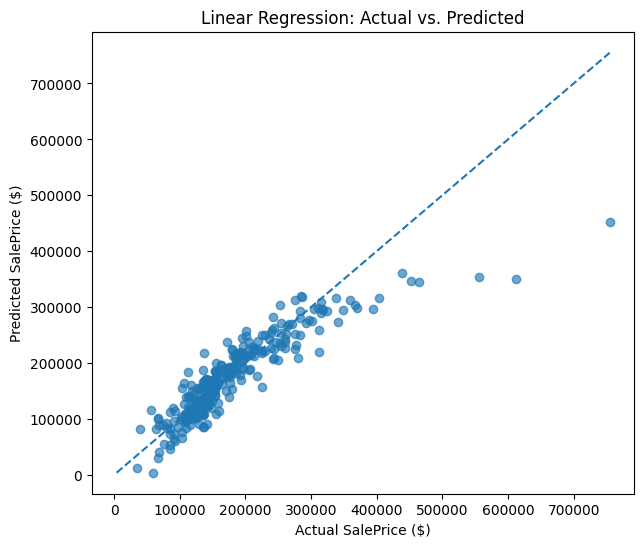

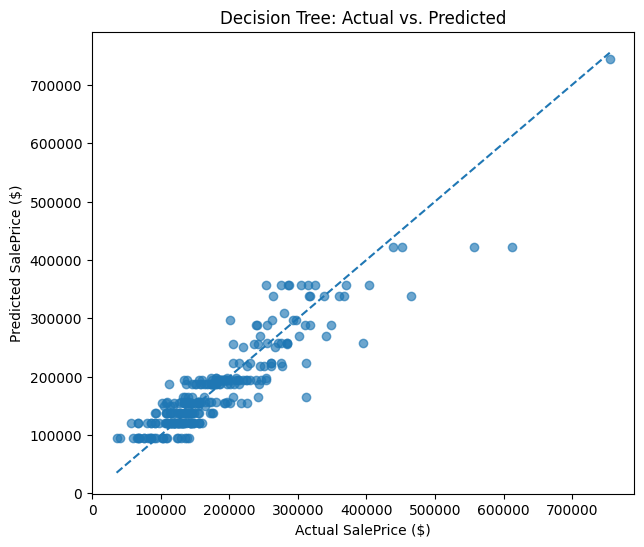

In [25]:
models_reg = {
    "Linear Regression": linear_scaled,
    "Decision Tree": tree_scaled
}

for name, model in models_reg.items():
    pred = model.predict(Xh_test)

    plt.figure(figsize=(7, 6))
    plt.scatter(yh_test, pred, alpha=0.65)

    low = min(yh_test.min(), pred.min())
    high = max(yh_test.max(), pred.max())

    plt.plot([low, high], [low, high], linestyle="--")

    plt.xlabel("Actual SalePrice ($)")
    plt.ylabel("Predicted SalePrice ($)")
    plt.title(name + ": Actual vs. Predicted")
    plt.show()


### Reading this plot

The dashed diagonal represents **perfect predictions**.

- Points on the line: prediction = actual price.
- Points above the line: model overestimates.
- Points below the line: model underestimates.

Look especially at the most expensive houses. Are errors larger there?


## 21. Decision Tree Regression feature importance


In [26]:
tree_model = tree_unscaled_reg.named_steps["model"]

reg_importance = pd.Series(
    tree_model.feature_importances_,
    index=features
).sort_values(ascending=False)

display(reg_importance.to_frame("importance"))


,importance
OverallQual,0.748370
GrLivArea,0.111602
TotalBsmtSF,0.053820
YearRemodAdd,0.025317
1stFlrSF,0.020822
YearBuilt,0.017151
FullBath,0.010944
GarageCars,0.006752
TotRmsAbvGrd,0.005222


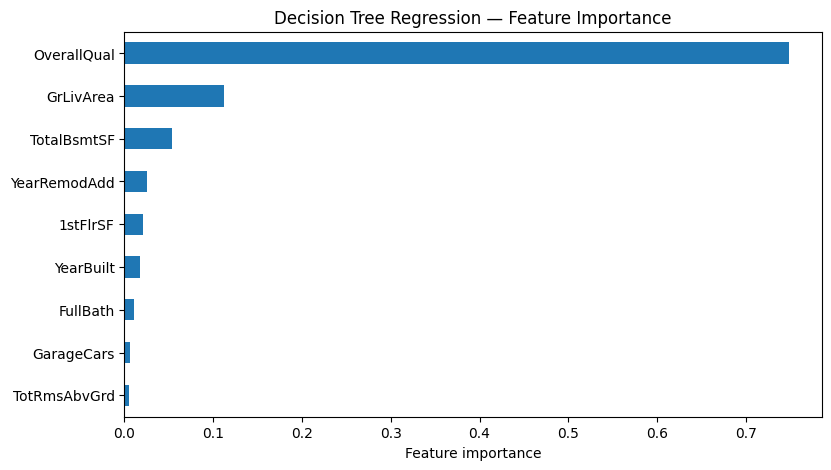

In [27]:
plt.figure(figsize=(9, 5))

reg_importance.sort_values().plot(kind="barh")

plt.xlabel("Feature importance")
plt.title("Decision Tree Regression — Feature Importance")
plt.show()


### Challenge 4

Which feature does the tree rely on most?

Now answer carefully:

**Does high feature importance mean that this feature causes higher house prices?**

Explain why or why not.


## 22. Tree depth: underfitting vs. overfitting in regression


In [28]:
reg_depth_results = []

for depth in range(1, 21):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(
            max_depth=depth,
            random_state=42
        ))
    ])

    model.fit(Xh_train, yh_train)

    train_pred = model.predict(Xh_train)
    test_pred = model.predict(Xh_test)

    reg_depth_results.append({
        "max_depth": depth,
        "Train RMSE": np.sqrt(
            mean_squared_error(yh_train, train_pred)
        ),
        "Test RMSE": np.sqrt(
            mean_squared_error(yh_test, test_pred)
        )
    })

reg_depth_df = pd.DataFrame(reg_depth_results)
display(reg_depth_df)


,max_depth,Train RMSE,Test RMSE
0,1,56940.134577,65179.178177
1,2,47488.207036,50731.027707
2,3,40552.843628,43364.231509
3,4,34438.563003,39445.594508
4,5,29620.211787,35694.214805
5,6,24981.168121,35293.114525
6,7,21094.682511,34788.642049
7,8,17516.395021,36026.804562
8,9,14461.037869,35570.233049
9,10,11876.631967,36363.166611


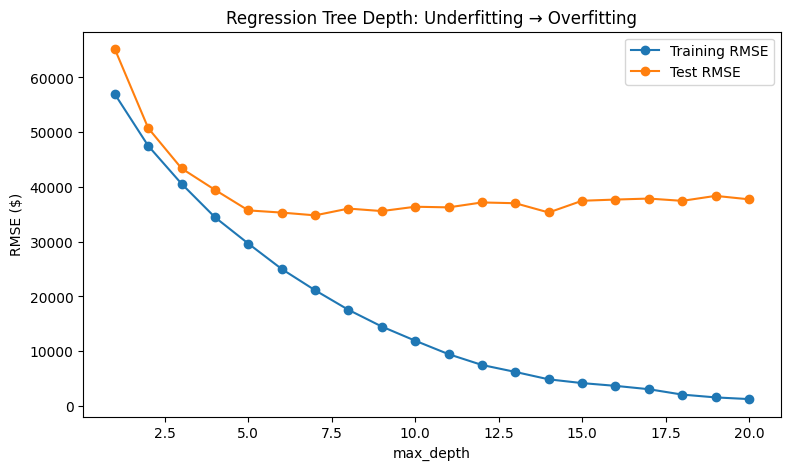

In [29]:
plt.figure(figsize=(9, 5))

plt.plot(
    reg_depth_df["max_depth"],
    reg_depth_df["Train RMSE"],
    marker="o",
    label="Training RMSE"
)

plt.plot(
    reg_depth_df["max_depth"],
    reg_depth_df["Test RMSE"],
    marker="o",
    label="Test RMSE"
)

plt.xlabel("max_depth")
plt.ylabel("RMSE ($)")
plt.title("Regression Tree Depth: Underfitting → Overfitting")
plt.legend()
plt.show()


### Challenge 5

1. What happens to training RMSE as depth increases?
2. What happens to test RMSE?
3. At which point does the gap between training and test error become large?
4. Why can a fully grown tree achieve extremely low training error but worse test performance?


你的理解方向是對的，而且還可以再更嚴格一點：feature importance 連「關聯」都說得比較弱，它只說**這棵樹在這份資料上，覺得這個欄位拿來切很有用**。

第一個問題「最依賴哪個特徵」，直接看你 importance 表格的第一列就好。下面說明為什麼它不代表因果。

## 三個層次

| 說法 | importance 能不能支持 |
|---|---|
| 「這棵樹切分時最常、最有效地用到它」 | 能，這就是定義 |
| 「它跟房價有關聯」 | 大致可以，但有例外（見下面第 4 點） |
| 「提高它會讓房價變高」 | 不能 |

## 為什麼不能說是因果

**1. 混淆變數（confounding）**

假設「浴室數量」重要性很高。但浴室多的房子通常面積也大、地段也好，真正推高房價的可能是面積和地段，浴室只是跟著出現。你在現有房子裡多加一間浴室，房價不見得會像模型暗示的那樣上漲。

**2. 反向因果**

如果資料裡有「每年房屋稅」，它的重要性一定很高，因為稅是根據房價算的。方向是房價造成稅，不是稅造成房價。模型只看到兩者一起變動，分不出誰影響誰。

**3. importance 沒有方向**

題目問的是「造成**更高**的房價」，但 importance 只是一個非負的分數，沒有正負號。它不告訴你這個特徵越高房價越高還是越低，甚至可能是非單調的：樹可能在「中間值」切出高價區，兩端都是低價。

**4. 模型本身的偏差**

之前講過的幾個問題也會影響 importance：

- 高度相關的欄位會分走功勞。例如面積和房間數很相關，樹可能只用其中一個，另一個的重要性就被低估，但它跟房價的關聯其實一樣強。
- 取值多的連續欄位比較容易被選中。
- 換一個 `max_depth` 或 `random_state`，排名可能就變了。

所以即使是「關聯強度」，importance 也不是很準的量尺。

## 預測問題 vs 因果問題

這兩個是不同的問題：

- **預測**：「知道 X 之後，能不能把房價猜得更準？」這是 importance 在回答的。
- **因果**：「如果我**改變** X，房價會不會跟著變？」這需要實驗（隨機分配），或是因果推論方法（明確假設混淆變數是什麼並加以控制），光靠預測模型的 importance 回答不了。

## 如果要寫進 notebook

> No. Feature importance measures how much a feature reduced prediction error (impurity) in *this* tree on *this* data. It reflects predictive usefulness, not causation. A feature can be important because it is correlated with a true cause (confounding), because price influences it (reverse causality, e.g. property tax), or because of model artifacts (correlated features sharing credit, bias toward high-cardinality features, instability across random seeds). Importance also has no sign, so it cannot say whether increasing the feature raises or lowers price. Establishing causation requires experiments or causal-inference methods, not a predictive model's importance scores.


## 23. Challenge: tune the regression tree


In [30]:
reg_grid = GridSearchCV(
    Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("tree", DecisionTreeRegressor(random_state=42))
    ]),
    param_grid={
        "tree__max_depth": [3, 4, 5, 6, 8, 10, None],
        "tree__min_samples_leaf": [1, 2, 5, 10, 20],
        "tree__min_samples_split": [2, 5, 10, 20]
    },
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

reg_grid.fit(Xh_train, yh_train)

print("Best parameters:")
print(reg_grid.best_params_)

print(
    "\nBest CV RMSE:",
    round(-reg_grid.best_score_, 2)
)

print(
    "Test RMSE:",
    round(
        np.sqrt(
            mean_squared_error(
                yh_test,
                reg_grid.predict(Xh_test)
            )
        ),
        2
    )
)


Best parameters:
{'tree__max_depth': 10, 'tree__min_samples_leaf': 5, 'tree__min_samples_split': 20}

Best CV RMSE: 37700.85
Test RMSE: 36710.69
